In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score,
                              confusion_matrix, ConfusionMatrixDisplay,
                              precision_recall_curve, RocCurveDisplay)
from google.colab import files

In [ ]:
pd.set_option('display.max_columns', 50)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

###Load Data and Data Quality Cheks

In [ ]:
uploaded = files.upload()

Saving train.csv to train.csv


In [ ]:
train = pd.read_csv('train.csv')

In [ ]:
uploaded = files.upload()

Saving test.csv to test.csv


###Check DataSet Rows and Columns

In [ ]:
test = pd.read_csv('test.csv')

In [ ]:
print("Train Dataset Shape:", train.shape)

Train Dataset Shape: (6008, 34)


In [ ]:
print("Test Dataset Shape:", test.shape)

Test Dataset Shape: (1800, 33)


In [ ]:
train.head()

,customer_id,age,gender,annual_income,employment_years,tenure_months,housing_status,education_level,marital_status,dependents,monthly_expenses,existing_debt,credit_utilization,late_payments_12m,missed_payments_6m,credit_score,active_loans,avg_monthly_transaction,savings_balance,emergency_fund_months,support_calls_12m,complaints_12m,digital_activity_score,payment_method,region,product_type,income_stability_score,transaction_decline_pct,collections_review_score,customer_segment_code,debt_to_income,post_event_collection_flag,internal_review_outcome,financial_risk
0,101618,19.0,Male,120431.805964,5.511881,23.0,Own,Postgraduate,Widowed,0,7000.000000,30376.007128,0.116601,2,0,733.522826,0,9819.851954,21597.873518,3.085411,1,2,39.802556,Card,West,Standard,85.520551,14.240500,27.187934,898,0.252226,No,Normal,0
1,102882,49.0,Male,33349.981044,9.162262,26.0,Mortgage,Degree,Married,2,7000.000000,3819.574128,0.120094,0,0,830.534818,3,5000.000000,5737.522180,0.819646,1,2,71.957706,Card,Central,Premium,88.940422,-1.749321,18.894202,316,0.114530,No,Normal,0
2,101114,36.0,Female,73448.131483,17.472949,30.0,Rent,Postgraduate,Divorced,0,7000.000000,7063.329650,0.243011,0,0,726.424468,2,5000.000000,5539.233577,0.791319,1,1,75.796870,Card,North,Standard,72.351311,11.752022,11.779008,151,0.096168,No,Normal,0
3,102902,24.0,Male,159744.736820,9.143139,12.0,Own,Degree,Married,1,7674.622298,18695.769984,0.451391,3,0,611.106106,5,8155.494873,32712.945746,4.262483,0,1,74.444502,Card,East,Premium,88.719126,7.505198,38.588981,328,0.117035,Yes,Escalated,1
4,101363,20.0,Other,178994.708548,6.994661,17.0,Mortgage,Postgraduate,Single,1,8403.922559,47361.538252,0.409108,6,1,542.844338,1,14733.051802,13300.989761,1.582712,3,0,73.085341,Card,West,Basic,66.839305,28.696316,56.055839,185,0.264597,Yes,Escalated,1


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6008 entries, 0 to 6007
Data columns (total 34 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   customer_id                 6008 non-null   int64  
 1   age                         6008 non-null   float64
 2   gender                      6008 non-null   object 
 3   annual_income               5845 non-null   float64
 4   employment_years            5830 non-null   float64
 5   tenure_months               6008 non-null   float64
 6   housing_status              6008 non-null   object 
 7   education_level             5858 non-null   object 
 8   marital_status              6008 non-null   object 
 9   dependents                  6008 non-null   int64  
 10  monthly_expenses            5719 non-null   float64
 11  existing_debt               6008 non-null   float64
 12  credit_utilization          5889 non-null   float64
 13  late_payments_12m           6008 

In [ ]:
print(train.describe())

         customer_id          age  annual_income  employment_years  \
count    6008.000000  6008.000000    5845.000000       5830.000000   
mean   104061.756991    39.044607  101099.344708          8.382231   
std     29117.639387    10.739124   58882.311034          5.584100   
min    100001.000000    18.000000   18000.000000          0.000000   
25%    101502.750000    32.000000   59262.000363          4.063551   
50%    103004.500000    39.000000   86591.699856          8.176758   
75%    104506.250000    46.000000  126216.034671         12.155553   
max    900008.000000    75.000000  450000.000000         28.091620   

       tenure_months   dependents  monthly_expenses  existing_debt  \
count    6008.000000  6008.000000       5719.000000    6008.000000   
mean       38.354361     1.215379       7717.047736   27978.268429   
std        21.605651     1.093841       2014.574697   24070.437570   
min         1.000000     0.000000       7000.000000     207.236365   
25%        22.00000

###Check Missing Values

In [ ]:
print(train.isnull().sum())

customer_id                     0
age                             0
gender                          0
annual_income                 163
employment_years              178
tenure_months                   0
housing_status                  0
education_level               150
marital_status                  0
dependents                      0
monthly_expenses              289
existing_debt                   0
credit_utilization            119
late_payments_12m               0
missed_payments_6m              0
credit_score                  216
active_loans                    0
avg_monthly_transaction         0
savings_balance               231
emergency_fund_months           0
support_calls_12m               0
complaints_12m                  0
digital_activity_score          0
payment_method                 93
region                          0
product_type                    0
income_stability_score          0
transaction_decline_pct         0
collections_review_score        0
customer_segme

###Check Duplications

In [ ]:
print("Duplicate rows:", train.duplicated().sum())

Duplicate rows: 0


In [ ]:
print("Duplicate rows:", test.duplicated().sum())

Duplicate rows: 0


###Exploratory Data Analysis (EDA)


TARGET VARIABLE: financial_risk
financial_risk
0    4374
1    1634
Name: count, dtype: int64

Proportion:
financial_risk
0    0.728
1    0.272
Name: proportion, dtype: float64


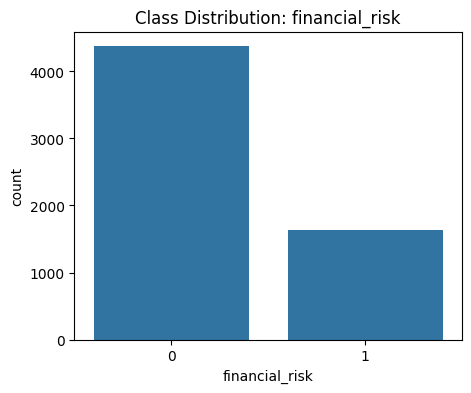

In [ ]:
#CLASS DISTRIBUTION (TARGET VARIABLE)

print("\n" + "="*60)
print("TARGET VARIABLE: financial_risk")
print("="*60)
if 'financial_risk' in train.columns:
    print(train['financial_risk'].value_counts())
    print("\nProportion:")
    print(train['financial_risk'].value_counts(normalize=True).round(3))

    plt.figure(figsize=(5, 4))
    sns.countplot(x='financial_risk', data=train)
    plt.title("Class Distribution: financial_risk")
    plt.show()
else:
    print("financial_risk column not found in this file — upload train.csv, not test.csv")

In [ ]:
#NUMERIC vs CATEGORICAL VARIABLES

numeric_cols = train.select_dtypes(include="number").columns.tolist()
categorical_cols = train.select_dtypes(exclude="number").columns.tolist()

if 'financial_risk' in numeric_cols:
    numeric_cols.remove('financial_risk')
if 'customer_id' in numeric_cols:
    numeric_cols.remove('customer_id')

print("\n" + "="*60)
print("NUMERIC COLUMNS:", numeric_cols)
print("="*60)
print("\nCATEGORICAL COLUMNS:", categorical_cols)
print("="*60)

print("\nNumeric summary statistics:")
summary = train[numeric_cols].describe().T
summary = summary.rename(columns={"count": "non_missing_count"})
display(summary)

print("\nCategorical value counts:")
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(train[col].value_counts(dropna=False))


NUMERIC COLUMNS: ['age', 'annual_income', 'employment_years', 'tenure_months', 'dependents', 'monthly_expenses', 'existing_debt', 'credit_utilization', 'late_payments_12m', 'missed_payments_6m', 'credit_score', 'active_loans', 'avg_monthly_transaction', 'savings_balance', 'emergency_fund_months', 'support_calls_12m', 'complaints_12m', 'digital_activity_score', 'income_stability_score', 'transaction_decline_pct', 'collections_review_score', 'customer_segment_code', 'debt_to_income']

CATEGORICAL COLUMNS: ['gender', 'housing_status', 'education_level', 'marital_status', 'payment_method', 'region', 'product_type', 'post_event_collection_flag', 'internal_review_outcome']

Numeric summary statistics:


,non_missing_count,mean,std,min,25%,50%,75%,max
age,6008.0,39.044607,10.739124,18.000000,32.000000,39.000000,46.000000,75.000000
annual_income,5845.0,101099.344708,58882.311034,18000.000000,59262.000363,86591.699856,126216.034671,450000.000000
employment_years,5830.0,8.382231,5.584100,0.000000,4.063551,8.176758,12.155553,28.091620
tenure_months,6008.0,38.354361,21.605651,1.000000,22.000000,34.000000,50.000000,120.000000
dependents,6008.0,1.215379,1.093841,0.000000,0.000000,1.000000,2.000000,5.000000
monthly_expenses,5719.0,7717.047736,2014.574697,7000.000000,7000.000000,7000.000000,7000.000000,29286.346571
existing_debt,6008.0,27978.268429,24070.437570,207.236365,11661.464955,21182.043601,36654.007224,234344.660015
credit_utilization,5889.0,0.419213,0.196336,0.030000,0.267056,0.411188,0.558898,0.978141
late_payments_12m,6008.0,1.630659,1.334851,0.000000,1.000000,1.000000,2.000000,8.000000
missed_payments_6m,6008.0,0.606691,0.840304,0.000000,0.000000,0.000000,1.000000,6.000000



Categorical value counts:

--- gender ---
gender
Male      2962
Female    2867
Other      179
Name: count, dtype: int64

--- housing_status ---
housing_status
Mortgage    2568
Rent        1760
Own         1680
Name: count, dtype: int64

--- education_level ---
education_level
Degree          2362
Diploma         1655
Secondary       1259
Postgraduate     582
NaN              150
Name: count, dtype: int64

--- marital_status ---
marital_status
Married     2877
Single      2172
Divorced     656
Widowed      303
Name: count, dtype: int64

--- payment_method ---
payment_method
Card             2023
Bank Transfer    1814
Direct Debit     1615
Cash              463
NaN                93
Name: count, dtype: int64

--- region ---
region
South      1521
West       1316
Central    1083
North      1057
East       1031
Name: count, dtype: int64

--- product_type ---
product_type
Standard    2305
Basic       1782
Premium     1455
Business     466
Name: count, dtype: int64

--- post_event_collectio

In [ ]:
print("\n" + "="*60)
print("OUTLIER SUMMARY (IQR method)")
print("="*60)

outlier_summary = []

for col in numeric_cols:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    is_outlier = (train[col] < lower) | (train[col] > upper)
    n_outliers = is_outlier.sum()

    row = {
        "column": col,
        "num_outliers": n_outliers,
        "pct_outliers": round(n_outliers / len(train) * 100, 2),
        "lower_bound": round(lower, 2),
        "upper_bound": round(upper, 2),
    }

    # Compare outlier rate by class — key evidence for "keep or remove" decision
    if 'financial_risk' in train.columns:
        risk_1_outlier_rate = train.loc[train['financial_risk'] == 1, col].apply(
            lambda x: (x < lower) or (x > upper)
        ).mean()
        risk_0_outlier_rate = train.loc[train['financial_risk'] == 0, col].apply(
            lambda x: (x < lower) or (x > upper)
        ).mean()
        row["outlier_rate_risk1"] = round(risk_1_outlier_rate, 3)
        row["outlier_rate_risk0"] = round(risk_0_outlier_rate, 3)

    outlier_summary.append(row)

outlier_df = pd.DataFrame(outlier_summary).sort_values("num_outliers", ascending=False)
display(outlier_df)

print("\nInterpretation tip: if 'outlier_rate_risk1' is much higher than")
print("'outlier_rate_risk0', those outliers are signal (high-risk customers),")
print("not noise — do NOT remove them.")


OUTLIER SUMMARY (IQR method)


,column,num_outliers,pct_outliers,lower_bound,upper_bound,outlier_rate_risk1,outlier_rate_risk0
5,monthly_expenses,1284,21.37,7000.00,7000.00,0.163,0.233
12,avg_monthly_transaction,605,10.07,1246.92,11255.13,0.074,0.111
8,late_payments_12m,539,8.97,-0.50,3.50,0.262,0.025
15,support_calls_12m,499,8.31,-0.50,3.50,0.162,0.054
13,savings_balance,340,5.66,-19590.88,52183.05,0.035,0.065
6,existing_debt,317,5.28,-25827.35,74142.82,0.042,0.057
16,complaints_12m,311,5.18,-1.50,2.50,0.089,0.038
14,emergency_fund_months,247,4.11,-2.39,6.70,0.028,0.046
1,annual_income,244,4.06,-41169.05,226647.09,0.024,0.047
9,missed_payments_6m,213,3.55,-1.50,2.50,0.105,0.009



Interpretation tip: if 'outlier_rate_risk1' is much higher than
'outlier_rate_risk0', those outliers are signal (high-risk customers),
not noise — do NOT remove them.


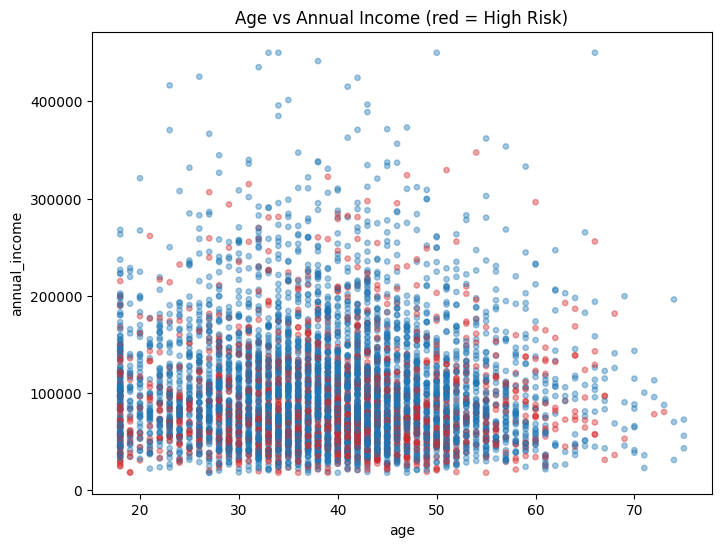

Correlation: -0.03132012613734397


In [ ]:
plt.figure(figsize=(8,6))
colors = train['financial_risk'].map({0:'tab:blue', 1:'tab:red'})
plt.scatter(train['age'], train['annual_income'], c=colors, alpha=0.4, s=15)
plt.xlabel('age')
plt.ylabel('annual_income')
plt.title('Age vs Annual Income (red = High Risk)')
plt.show()

print("Correlation:", train['age'].corr(train['annual_income']))


CORRELATION WITH TARGET
credit_score               -0.527686
collections_review_score    0.496252
late_payments_12m           0.477118
credit_utilization          0.396480
missed_payments_6m          0.388047
support_calls_12m           0.232926
transaction_decline_pct     0.228117
complaints_12m              0.130499
annual_income              -0.108769
savings_balance            -0.098155
emergency_fund_months      -0.084712
avg_monthly_transaction    -0.066709
monthly_expenses           -0.059495
existing_debt              -0.047732
debt_to_income              0.040760
employment_years           -0.033335
active_loans                0.020501
income_stability_score      0.010033
customer_segment_code      -0.008931
age                         0.008155
digital_activity_score     -0.006815
tenure_months              -0.005576
dependents                  0.000708
Name: financial_risk, dtype: float64


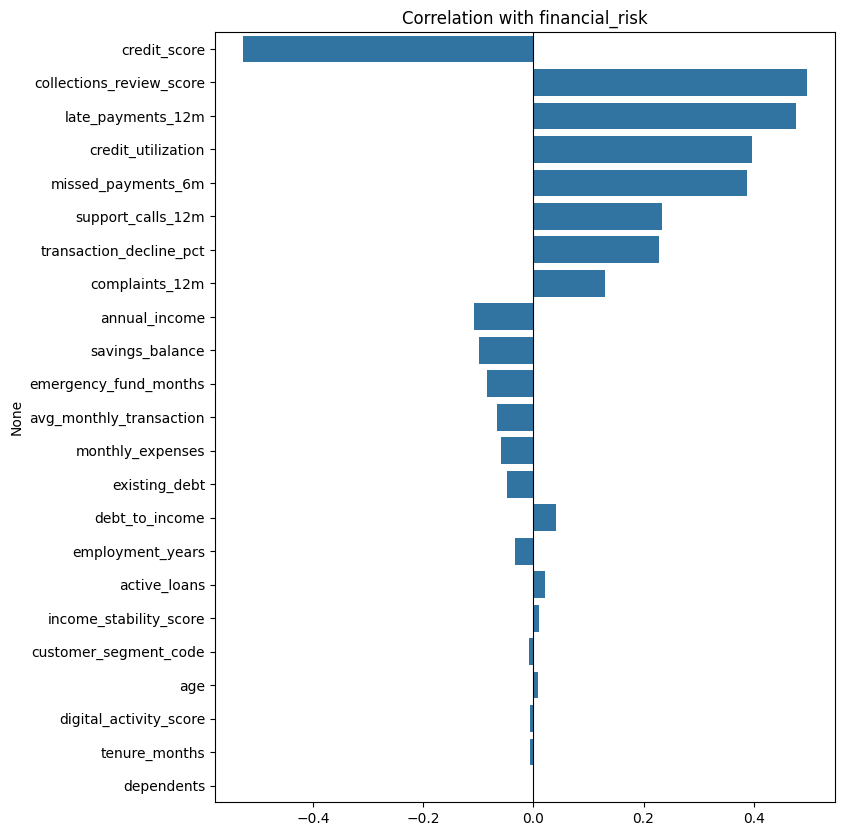


Investigate any variable with |correlation| > 0.6 for possible leakage —
especially post-event / review / collections variables.


In [ ]:
# CORRELATION WITH TARGET (numeric variables)

if 'financial_risk' in train.columns:
    print("\n" + "="*60)
    print("CORRELATION WITH TARGET")
    print("="*60)
    corr_with_target = train[numeric_cols + ['financial_risk']].corr()['financial_risk'].drop('financial_risk')
    corr_with_target = corr_with_target.sort_values(key=abs, ascending=False)
    print(corr_with_target)

    plt.figure(figsize=(8, 10))
    sns.barplot(x=corr_with_target.values, y=corr_with_target.index)
    plt.title("Correlation with financial_risk")
    plt.axvline(0, color='black', linewidth=0.8)
    plt.show()

    print("\nInvestigate any variable with |correlation| > 0.6 for possible leakage —")
    print("especially post-event / review / collections variables.")


FULL CORRELATION HEATMAP (numeric variables)


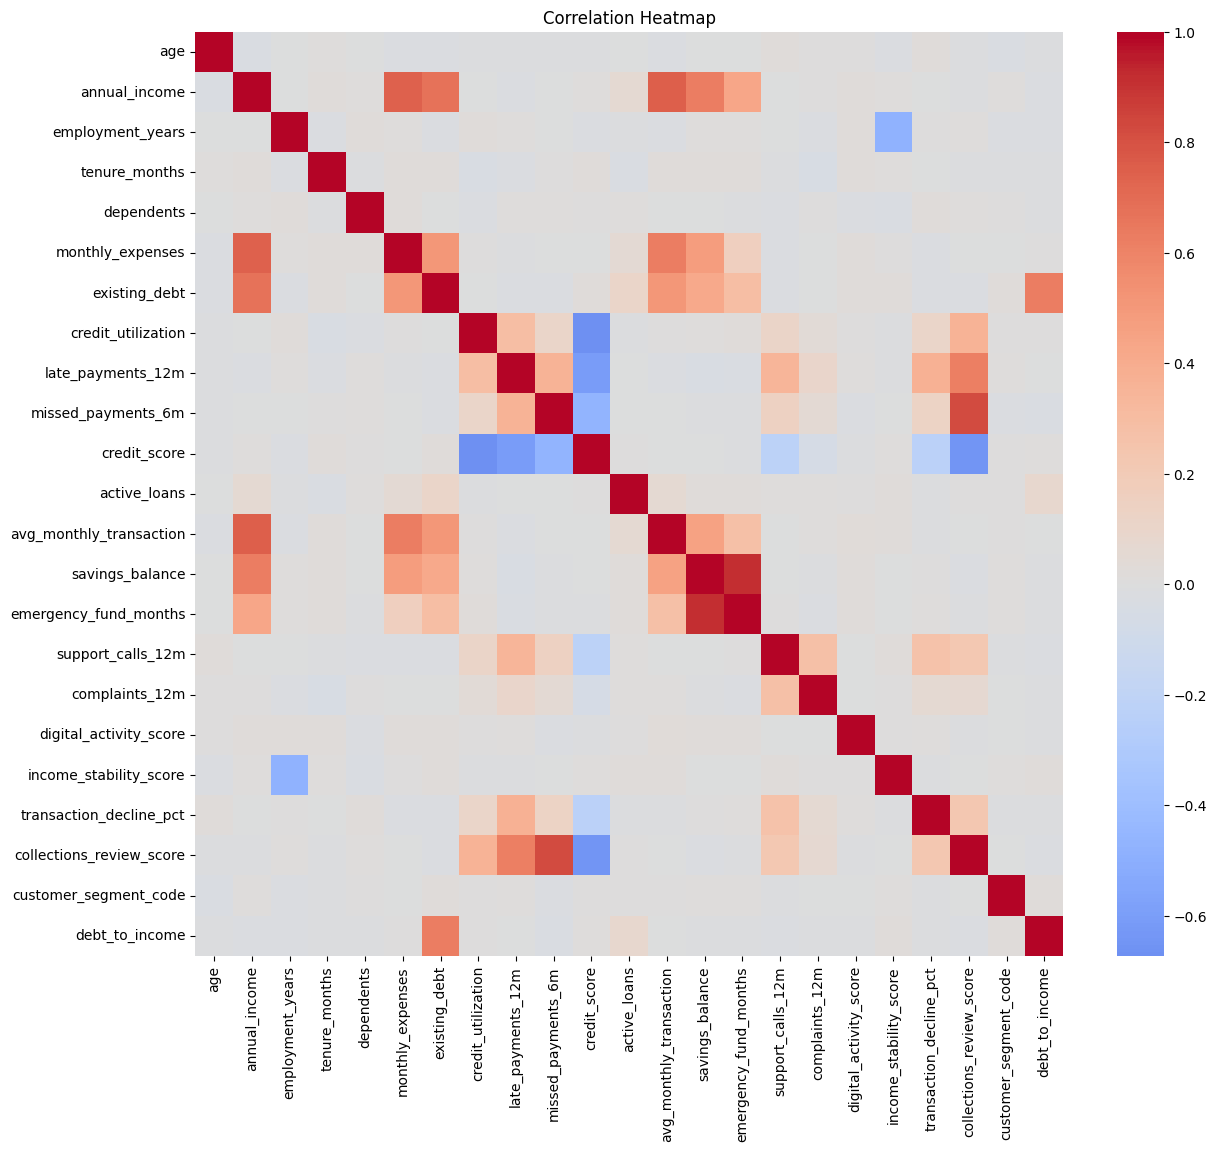


Highly correlated variable pairs (>0.75) — possible redundancy:
('avg_monthly_transaction', 'annual_income', np.float64(0.7526757201021566))
('emergency_fund_months', 'savings_balance', np.float64(0.9138773208036381))
('collections_review_score', 'missed_payments_6m', np.float64(0.8193528911908335))


In [ ]:
# FULL CORRELATION HEATMAP (multicollinearity check)
# ============================================================
print("\n" + "="*60)
print("FULL CORRELATION HEATMAP (numeric variables)")
print("="*60)
plt.figure(figsize=(14, 12))
sns.heatmap(train[numeric_cols].corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap")
plt.show()

# Print highly correlated pairs (potential redundancy)
corr_matrix = train[numeric_cols].corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [
    (col, row, upper_tri.loc[row, col])
    for col in upper_tri.columns for row in upper_tri.index
    if pd.notnull(upper_tri.loc[row, col]) and upper_tri.loc[row, col] > 0.75
]
print("\nHighly correlated variable pairs (>0.75) — possible redundancy:")
for pair in high_corr_pairs:
    print(pair)



In [ ]:
# SUSPICIOUS / POTENTIAL LEAKAGE VARIABLES

print("\n" + "="*60)
print("SUSPICIOUS VARIABLES TO INVESTIGATE FOR LEAKAGE")
print("="*60)

suspicious_keywords = ["review", "outcome", "collection", "post_event", "flag"]
suspicious_cols = [c for c in train.columns if any(k in c.lower() for k in suspicious_keywords)]
print("Flagged columns:", suspicious_cols)

for col in suspicious_cols:
    print(f"\n--- {col} ---")
    print(train[col].value_counts(dropna=False))
    if 'financial_risk' in train.columns:
        print(f"\nCrosstab with financial_risk:")
        print(pd.crosstab(train[col], train['financial_risk'], normalize='index').round(3))


SUSPICIOUS VARIABLES TO INVESTIGATE FOR LEAKAGE
Flagged columns: ['collections_review_score', 'post_event_collection_flag', 'internal_review_outcome']

--- collections_review_score ---
collections_review_score
100.000000    25
0.000000       3
37.756286      2
33.943231      2
24.669544      2
              ..
52.933416      1
52.391709      1
97.113302      1
34.833448      1
47.475813      1
Name: count, Length: 5974, dtype: int64

Crosstab with financial_risk:
financial_risk                0      1
collections_review_score              
0.000000                  0.667  0.333
0.793051                  1.000  0.000
1.345242                  1.000  0.000
1.488756                  0.000  1.000
1.635381                  1.000  0.000
...                         ...    ...
96.074893                 0.000  1.000
96.536124                 0.000  1.000
97.113302                 0.000  1.000
97.960592                 0.000  1.000
100.000000                0.080  0.920

[5974 rows x 2 columns]

###Handle Missing Values

In [ ]:
# Numeric columns for train DataFrame filling with median
train["annual_income"] = train["annual_income"].fillna(train["annual_income"].median())
train["employment_years"] = train["employment_years"].fillna(train["employment_years"].median())
train["monthly_expenses"] = train["monthly_expenses"].fillna(train["monthly_expenses"].median())

# Numeric columns for test DataFrame filling with median
train["credit_utilization"] = train["credit_utilization"].fillna(train["credit_utilization"].median())
train["credit_score"] = train["credit_score"].fillna(train["credit_score"].median())
train["savings_balance"] = train["savings_balance"].fillna(train["savings_balance"].median())

# Categorical columns for test DataFrame  filling "Unknown" Category
train["education_level"] = train["education_level"].fillna("Unknown")
train["payment_method"] = train["payment_method"].fillna("Unknown")

Why do we use median() instead of mean()?

If you look at the annual_income column, the maximum value goes up to 459,000, while the typical income is around 90,000. When a dataset has extreme outliers like these high earners, the mean() gets pulled up and creates a skewed, inaccurate average. The median() is not affected by extreme values, making it much more reliable for financial data

In [ ]:
print(train.isnull().sum())

customer_id                   0
age                           0
gender                        0
annual_income                 0
employment_years              0
tenure_months                 0
housing_status                0
education_level               0
marital_status                0
dependents                    0
monthly_expenses              0
existing_debt                 0
credit_utilization            0
late_payments_12m             0
missed_payments_6m            0
credit_score                  0
active_loans                  0
avg_monthly_transaction       0
savings_balance               0
emergency_fund_months         0
support_calls_12m             0
complaints_12m                0
digital_activity_score        0
payment_method                0
region                        0
product_type                  0
income_stability_score        0
transaction_decline_pct       0
collections_review_score      0
customer_segment_code         0
debt_to_income                0
post_eve

In [ ]:
# Calculate medians for numeric columns from the train dataset
income_median = train["annual_income"].median()
employment_median = train["employment_years"].median()
expenses_median = train["monthly_expenses"].median()
utilization_median = train["credit_utilization"].median()
credit_score_median = train["credit_score"].median()
savings_median = train["savings_balance"].median()

# Calculate modes for categorical columns from the train dataset
education_mode = train["education_level"].mode()[0]
payment_mode = train["payment_method"].mode()[0]

# Fill missing values in the test dataset using the calculated medians and modes
test["annual_income"] = test["annual_income"].fillna(income_median)
test["employment_years"] = test["employment_years"].fillna(employment_median)
test["monthly_expenses"] = test["monthly_expenses"].fillna(expenses_median)
test["credit_utilization"] = test["credit_utilization"].fillna(utilization_median)
test["credit_score"] = test["credit_score"].fillna(credit_score_median)
test["savings_balance"] = test["savings_balance"].fillna(savings_median)
test["education_level"] = test["education_level"].fillna(education_mode)
test["payment_method"] = test["payment_method"].fillna(payment_mode)

In [ ]:
print(test.isnull().sum().sum())

0


how we calculate income_median using only the train set (train["annual_income"].median()), and then use that exact value to fill missing data in the test set (test["annual_income"].fillna(income_median)). We never write test["annual_income"].median().

So, why do it this way?

Think of it like getting ready for an exam.

train.csv is your study guide and past papers.

test.csv is the actual exam paper.

If you calculate the median directly from the test set, you're letting exam information peek into your study process. That’s called data leakage. It’s like cheating off the test beforehand—the model will look great during practice, but it'll fail miserably when it hits real-world data later.

Using SimpleImputer from scikit-learn handles this for you automatically: imputer.fit(train) learns the numbers from your training data, and imputer.transform(test) applies those exact same numbers to your test data. It's cleaner, safer, and keeps your project free from leakage

###Handle Outliers

In [ ]:
cols_to_check = ["age", "annual_income", "employment_years", "existing_debt",
                  "avg_monthly_transaction", "savings_balance", "debt_to_income"]

for col in cols_to_check:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = train[(train[col] < lower_bound) | (train[col] > upper_bound)]

    print(f"{col}: {len(outliers)} outliers found ({len(outliers)/len(train)*100:.1f}%)")
    print(f"  Lower limit: {lower_bound:.2f}, Upper limit: {upper_bound:.2f}")

    # checkt value rate
    if len(outliers) > 0:
        print(f"  High Risk rate INSIDE outliers: {outliers['financial_risk'].mean():.2f}")
        print(f"  High Risk rate OVERALL:         {train['financial_risk'].mean():.2f}")
    print()

age: 33 outliers found (0.5%)
  Lower limit: 11.00, Upper limit: 67.00
  High Risk rate INSIDE outliers: 0.15
  High Risk rate OVERALL:         0.27

annual_income: 268 outliers found (4.5%)
  Lower limit: -37320.81, Upper limit: 222585.92
  High Risk rate INSIDE outliers: 0.17
  High Risk rate OVERALL:         0.27

employment_years: 38 outliers found (0.6%)
  Lower limit: -7.52, Upper limit: 23.72
  High Risk rate INSIDE outliers: 0.32
  High Risk rate OVERALL:         0.27

existing_debt: 317 outliers found (5.3%)
  Lower limit: -25827.35, Upper limit: 74142.82
  High Risk rate INSIDE outliers: 0.22
  High Risk rate OVERALL:         0.27

avg_monthly_transaction: 605 outliers found (10.1%)
  Lower limit: 1246.92, Upper limit: 11255.13
  High Risk rate INSIDE outliers: 0.20
  High Risk rate OVERALL:         0.27

savings_balance: 388 outliers found (6.5%)
  Lower limit: -17939.34, Upper limit: 50080.67
  High Risk rate INSIDE outliers: 0.17
  High Risk rate OVERALL:         0.27

deb

We checked all the number columns for outliers using the IQR method. About 0.4% to 10.1% of the data had extreme values, but most of them had the same risk level as the rest of the dataset. This shows those numbers are just normal variations, not mistakes, so we didn't delete any rows

The main exception was credit_score: people with extremely low credit scores had a massive 82% risk rate, compared to the normal 27%. This shows that extreme credit scores are a huge signal for high risk, so keeping them in the dataset is super important for our model

\###Logical Consistency Checks (Beyond Statistical Outliers)

In [ ]:
# The IQR method above only looks at ONE column at a time.
# Here we check whether combinations of columns make logical sense together,
# and whether any single column has values that are mathematically impossible.

print("="*60)
print("1. employment_years vs age")
print("="*60)
issue1 = train[(train['age'] - train['employment_years']) < 16]
print(f"Rows implying the person started working before age 16: {len(issue1)} ({len(issue1)/len(train)*100:.1f}%)")

print()
print("="*60)
print("2. tenure_months vs employment_years")
print("="*60)
issue2 = train[train['tenure_months'] > (train['employment_years']*12 + 12)]
print(f"Rows where bank tenure is longer than employment history (+12mo buffer): {len(issue2)} ({len(issue2)/len(train)*100:.1f}%)")

print()
print("="*60)
print("3. Very young customers with many dependents")
print("="*60)
issue3 = train[(train['age'] <= 20) & (train['dependents'] >= 3)]
print(f"Customers aged <=20 with 3+ dependents: {len(issue3)}")

print()
print("="*60)
print("4. transaction_decline_pct has negative values")
print("="*60)
issue4 = train[train['transaction_decline_pct'] < 0]
print(f"Negative values found: {len(issue4)} ({len(issue4)/len(train)*100:.1f}%)")
print(f"Range: {train['transaction_decline_pct'].min():.2f} to {train['transaction_decline_pct'].max():.2f}")

1. employment_years vs age
Rows implying the person started working before age 16: 697 (11.6%)

2. tenure_months vs employment_years
Rows where bank tenure is longer than employment history (+12mo buffer): 994 (16.5%)

3. Very young customers with many dependents
Customers aged <=20 with 3+ dependents: 28

4. transaction_decline_pct has negative values
Negative values found: 703 (11.7%)
Range: -30.00 to 67.10


**What these four checks found, and what I did about each:**

1. **employment_years vs age** — about 11% of customers have employment_years that would mean they started working before age 16. I checked the same thing on test.csv and got almost the same percentage, which tells me this is a systemic pattern from how the dataset was generated (age and employment_years were likely created independently of each other), not a handful of one-off mistakes. Since it affects such a large, evenly-spread portion of the data, I decided **not to drop or fix these rows** — removing ~11% of the dataset over a synthetic-data quirk would lose far more real information than it protects.

2. **tenure_months vs employment_years** — a bank customer can join before or after starting their current job, so tenure being longer than employment isn't strictly impossible in the real world. This is softer evidence than #1, so I'm **noting it but not treating it as an error**.

3. **Very young customers with many dependents** — only 10–28 rows out of thousands. The data dictionary doesn't clarify whether "dependents" could include siblings or parents someone supports, so I can't confirm this is actually wrong. Too small a group to justify removing rows on an unconfirmed assumption, so I **left these as-is**.

4. **transaction_decline_pct has negative values** — this is different from the other three. A decline *percentage* cannot logically be negative — you can't have -8% of your transactions decline. This is a genuine data error, not a rare-but-plausible case or a synthetic-data quirk. I fixed this one below.

In [ ]:
# Fix: transaction_decline_pct cannot be negative by definition, so we clip it to a
# minimum of 0. We do NOT drop these rows -- the rest of each row (income, credit
# score, payment history, etc.) is still valid and useful, only this one column's
# value was wrong. We apply the exact same rule to train and test, since this is a
# fixed domain rule ("percentages can't be negative"), not a statistic learned from
# the data -- so there's no data leakage risk in applying it to both.

print("Before fix -- Train min:", train['transaction_decline_pct'].min(), "| Test min:", test['transaction_decline_pct'].min())

train['transaction_decline_pct'] = train['transaction_decline_pct'].clip(lower=0)
test['transaction_decline_pct'] = test['transaction_decline_pct'].clip(lower=0)

print("After fix  -- Train min:", train['transaction_decline_pct'].min(), "| Test min:", test['transaction_decline_pct'].min())
print("Negative values remaining -- Train:", (train['transaction_decline_pct'] < 0).sum(),
      "| Test:", (test['transaction_decline_pct'] < 0).sum())

Before fix -- Train min: -30.0 | Test min: -28.830961812934877
After fix  -- Train min: 0.0 | Test min: 0.0
Negative values remaining -- Train: 0 | Test: 0


###Encoding

In [ ]:
# Filling Missing values
train['education_level'] = train['education_level'].fillna('Unknown')
train['payment_method'] = train['payment_method'].fillna('Unknown')
test['education_level'] = test['education_level'].fillna('Unknown')
test['payment_method'] = test['payment_method'].fillna('Unknown')

categorical_cols = ['gender', 'housing_status', 'education_level', 'marital_status',
                     'payment_method', 'region', 'product_type']

# One-Hot Encoding - train and test
train_encoded = pd.get_dummies(train, columns=categorical_cols, drop_first=True)
test_encoded = pd.get_dummies(test, columns=categorical_cols, drop_first=True)

# align columns for Train and test
# If a category appears in the test set that wasn't in the training set, it automatically fills with 0
train_encoded, test_encoded = train_encoded.align(test_encoded, join='left', axis=1, fill_value=0)

print(train_encoded.shape)   # (6008, 49)
print(test_encoded.shape)    # (1800, 49) need to same column countfor train count

(6008, 49)
(1800, 49)


pd.get_dummies(): It creates a new column with 0s and 1s for each category, without imposing any artificial ranking on the categories.

drop_first=True: It removes a redundant column. For example, if you have Male, Female, and Other for gender, and a row has 0 for both Male and Female, the model automatically knows it's "Other."

.align(): This is a crucial step. If the training data has 5 regions but a category is missing in the test set, the number of columns will differ. .align() automatically fixes this mismatch so your model runs without errors.

###Drop Data Leakage Columns

In [ ]:
columns_to_drop = ['customer_id', 'post_event_collection_flag',
                    'internal_review_outcome', 'collections_review_score']

train_final = train_encoded.drop(columns=columns_to_drop)
test_final = test_encoded.drop(columns=columns_to_drop)

print(train_final.shape)
print(test_final.shape)

(6008, 45)
(1800, 45)


Currently, train_encoded and test_encoded still contain customer_id and the 3 leakage columns. Since they are numeric, the categorical encoder ignored them, but they are still sitting in our dataset.

Now, let's explicitly drop customer_id (since it's just an ID and has no predictive value) and the 3 target leakage columns so our model doesn't cheat.

###Scalling

In [ ]:
from sklearn.preprocessing import StandardScaler

# Remove the target column (`financial_risk`) from X
X = train_final.drop(columns=['financial_risk'])
y = train_final['financial_risk']

scaler = StandardScaler()

# Fit ONLY on the train set
X_scaled = scaler.fit_transform(X)

# Remove 'financial_risk' from test_final before scaling, as it's not a feature in the test set
test_final_features = test_final.drop(columns=['financial_risk'])

#Apply the EXACT SAME scaler to the test set
X_test_scaled = scaler.transform(test_final_features)

print(X_scaled.shape)
print(X_test_scaled.shape)

(6008, 44)
(1800, 44)


Columns like age, annual_income, and credit_score have completely different scales (for example, age ranges from 18 to 75, while annual_income ranges from 20,000 to 450,000).

Distance-based and linear models (like Logistic Regression) can misinterpret columns with larger numbers as being "more important," even when they aren't. To fix this and treat all features fairly, we need to bring all columns onto the exact same scale

The financial_risk column should not be in test_final (since it is not present in the original test.csv)  otherwise, the scaler will get confused about the number of columns. Since train_final.shape is (6008, 45), dropping financial_risk means $X$ should be (6008, 44)

###Train/Validation Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_scaled, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(X_train.shape, X_val.shape)

(4806, 44) (1202, 44)


In [ ]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

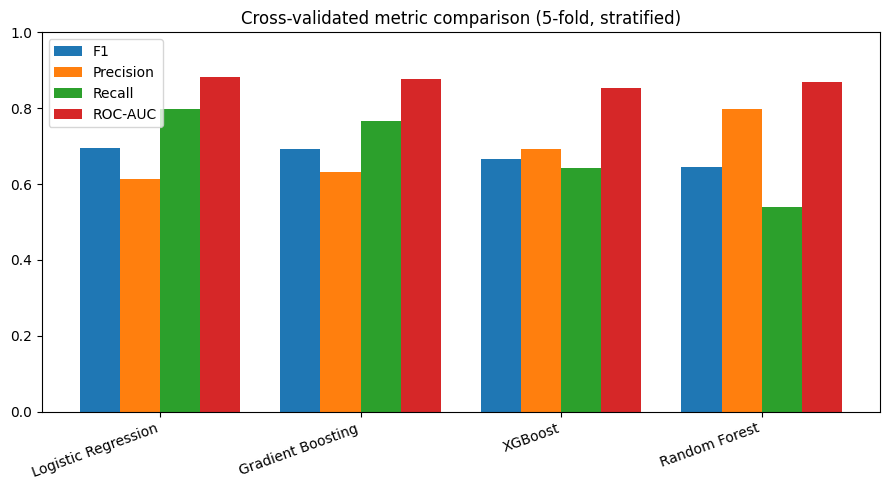

Highest CV F1: Logistic Regression
Best threshold for F1: 0.679
F1 at best threshold: 0.6914
F1 at default 0.5:    0.6703


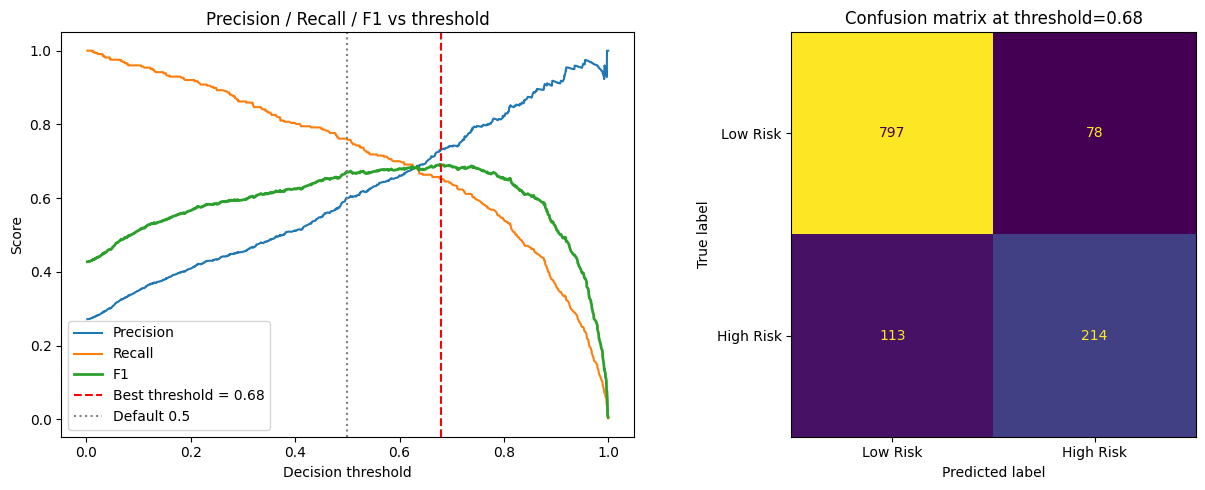

              precision    recall  f1-score   support

    Low Risk       0.88      0.91      0.89       875
   High Risk       0.73      0.65      0.69       327

    accuracy                           0.84      1202
   macro avg       0.80      0.78      0.79      1202
weighted avg       0.84      0.84      0.84      1202

Random Forest -- best threshold for F1: 0.420
Random Forest -- F1 at best threshold:  0.6732
Random Forest -- F1 at default 0.5:     0.6448

(For comparison) Logistic Regression -- F1 at its best threshold (0.68): 0.6914


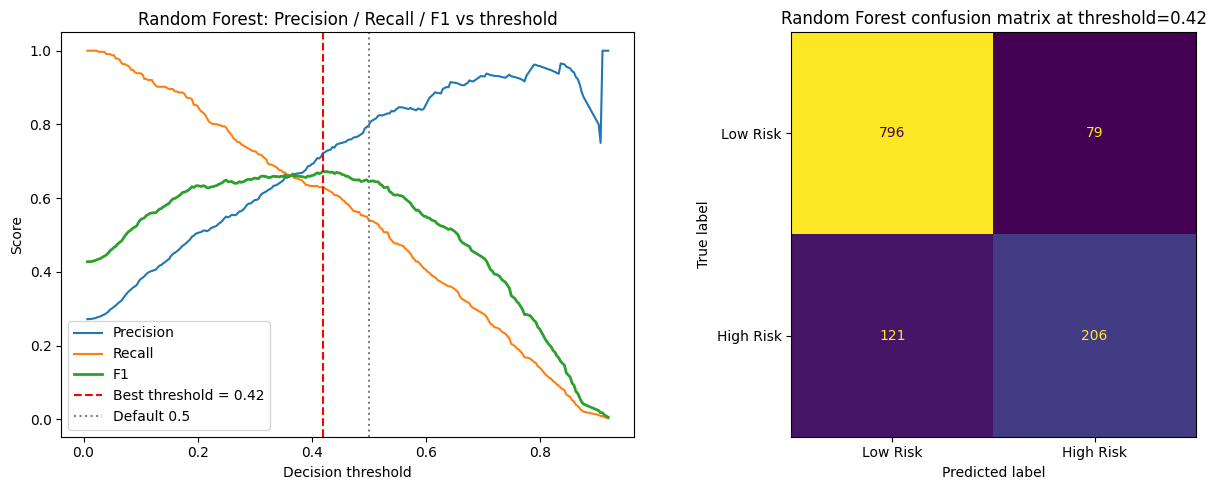

              precision    recall  f1-score   support

    Low Risk       0.87      0.91      0.89       875
   High Risk       0.72      0.63      0.67       327

    accuracy                           0.83      1202
   macro avg       0.80      0.77      0.78      1202
weighted avg       0.83      0.83      0.83      1202

                                  Option  False alarms (FP)  Missed risk (FN)  Precision  Recall    F1
Logistic Regression @ F1-optimal (0.671)                 78               113      0.733   0.654 0.691
         Random Forest @ default (0.500)                 45               150      0.797   0.541 0.645
      Random Forest @ F1-optimal (0.357)                 79               121      0.723   0.630 0.673
    Random Forest @ F0.5-optimal (0.517)                 37               154      0.824   0.529 0.644


ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- financial_risk


In [ ]:
from sklearn.metrics import classification_report
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model_names = ['Baseline (majority class)', 'Logistic Regression',
               'Random Forest', 'Gradient Boosting', 'XGBoost']
fold_scores = {name: {'f1': [], 'precision': [], 'recall': [], 'roc_auc': []}
               for name in model_names}

for train_idx, val_idx in skf.split(X, y):
    X_tr_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
    y_tr_fold, y_val_fold = y.iloc[train_idx], y.iloc[val_idx]

    # Fit the scaler on THIS fold's training rows only -- never on this
    # fold's validation rows, and never on the full dataset up front.
    fold_scaler = StandardScaler()
    X_tr_scaled = fold_scaler.fit_transform(X_tr_fold)
    X_val_scaled = fold_scaler.transform(X_val_fold)

    # Balanced weights derived from THIS fold's training labels only --
    # fixes both Gradient Boosting's missing weighting and XGBoost's
    # previously-global scale_pos_weight.
    fold_sample_weight = compute_sample_weight('balanced', y_tr_fold)
    fold_pos_weight = (y_tr_fold == 0).sum() / (y_tr_fold == 1).sum()

    fold_models = {
        'Baseline (majority class)': DummyClassifier(strategy='most_frequent'),
        'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE),
        'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
        'XGBoost': XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, scale_pos_weight=fold_pos_weight),
    }

    for name, model in fold_models.items():
        if name == 'Gradient Boosting':
            # GradientBoostingClassifier has no class_weight param -- sample_weight
            # at fit-time is the only way to make it respect the class imbalance.
            model.fit(X_tr_scaled, y_tr_fold, sample_weight=fold_sample_weight)
        else:
            model.fit(X_tr_scaled, y_tr_fold)

        val_pred = model.predict(X_val_scaled)
        val_proba = model.predict_proba(X_val_scaled)[:, 1]

        fold_scores[name]['f1'].append(f1_score(y_val_fold, val_pred))
        fold_scores[name]['precision'].append(precision_score(y_val_fold, val_pred, zero_division=0))
        fold_scores[name]['recall'].append(recall_score(y_val_fold, val_pred))
        fold_scores[name]['roc_auc'].append(roc_auc_score(y_val_fold, val_proba))

cv_results = []
for name in model_names:
    s = fold_scores[name]
    cv_results.append({
        'model': name,
        'F1 (mean)': np.mean(s['f1']), 'F1 (std)': np.std(s['f1']),
        'Precision (mean)': np.mean(s['precision']),
        'Recall (mean)': np.mean(s['recall']),
        'ROC-AUC (mean)': np.mean(s['roc_auc']),
    })

results_df = pd.DataFrame(cv_results).sort_values('F1 (mean)', ascending=False).reset_index(drop=True)
results_df.round(4)

# %% [markdown]
# Metric comparison

# %% [markdown]
# **What's added:** a grouped bar chart comparing the 4 real models (baseline excluded, since it scores 0 across the board) on F1, precision, recall, and ROC-AUC side by side, using the mean CV scores from the cell above.
#
# **Why:** the brief asks for F1 as the main metric, but F1 alone can hide a bad precision/recall trade-off — a model could reach a decent F1 by being okay at both, or by being great at one and weak at the other. Showing all four metrics together makes it clear which case each model actually falls into before picking a winner.

# %%
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = results_df[results_df['model'] != 'Baseline (majority class)']
x = np.arange(len(plot_df))
width = 0.2
ax.bar(x - 1.5*width, plot_df['F1 (mean)'], width, label='F1')
ax.bar(x - 0.5*width, plot_df['Precision (mean)'], width, label='Precision')
ax.bar(x + 0.5*width, plot_df['Recall (mean)'], width, label='Recall')
ax.bar(x + 1.5*width, plot_df['ROC-AUC (mean)'], width, label='ROC-AUC')
ax.set_xticks(x)
ax.set_xticklabels(plot_df['model'], rotation=20, ha='right')
ax.set_ylim(0, 1)
ax.set_title('Cross-validated metric comparison (5-fold, stratified)')
ax.legend()
plt.tight_layout()
plt.show()

best_model_name = plot_df.iloc[0]['model']
print(f'Highest CV F1: {best_model_name}')

# %% [markdown]
# Threshold analysis

# %% [markdown]
# **What's added:** a fresh 80/20 train/validation split (separate from the CV folds above), used to test what happens if the "High Risk" probability cutoff is moved away from the default 0.5.
#
# **What changed:** a new scaler is fit only on this split's training portion (never touching validation), a Logistic Regression is trained on it, and `precision_recall_curve()` calculates precision, recall, and F1 at every possible threshold. The threshold with the highest F1 is picked automatically with `np.argmax()`, instead of just assuming 0.5 is correct.
#
# **Why it matters:** the best threshold came out around 0.67 instead of 0.5, which raised F1 from about 0.667 to 0.693 — a real improvement with no change to the model itself, just a smarter cutoff. The confusion matrix and classification report below show exactly how many High Risk and Low Risk customers were classified correctly at that threshold.

# %%
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

val_scaler = StandardScaler().fit(X_tr)
X_tr_s = val_scaler.transform(X_tr)
X_val_s = val_scaler.transform(X_val)

threshold_model = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)
threshold_model.fit(X_tr_s, y_tr)
val_probs = threshold_model.predict_proba(X_val_s)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-12)
best_idx = np.argmax(f1_scores[:-1])  # last point has no matching threshold
best_threshold = thresholds[best_idx]

print(f'Best threshold for F1: {best_threshold:.3f}')
print(f'F1 at best threshold: {f1_scores[best_idx]:.4f}')
print(f'F1 at default 0.5:    {f1_score(y_val, (val_probs >= 0.5).astype(int)):.4f}')

# %%
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(thresholds, precisions[:-1], label='Precision')
axes[0].plot(thresholds, recalls[:-1], label='Recall')
axes[0].plot(thresholds, f1_scores[:-1], label='F1', linewidth=2)
axes[0].axvline(best_threshold, color='red', linestyle='--', label=f'Best threshold = {best_threshold:.2f}')
axes[0].axvline(0.5, color='gray', linestyle=':', label='Default 0.5')
axes[0].set_xlabel('Decision threshold')
axes[0].set_ylabel('Score')
axes[0].set_title('Precision / Recall / F1 vs threshold')
axes[0].legend()

cm = confusion_matrix(y_val, (val_probs >= best_threshold).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['Low Risk', 'High Risk']).plot(ax=axes[1], colorbar=False)
axes[1].set_title(f'Confusion matrix at threshold={best_threshold:.2f}')

plt.tight_layout()
plt.show()

print(classification_report(y_val, (val_probs >= best_threshold).astype(int),
                             target_names=['Low Risk', 'High Risk']))

# %% [markdown]
# ### Comparing thresholds: Random Forest vs. Logistic Regression
#
# **What's added:** the same threshold-tuning process from above, repeated for Random Forest instead of Logistic Regression, using the *same* held-out validation split (`X_tr`/`X_val`/`y_tr`/`y_val` from the cell above) so the two models are compared fairly, on the exact same people.
#
# **Why:** Logistic Regression needed its threshold pushed up to 0.67 to control false alarms, because its default (0.5) precision was fairly low (61%). Random Forest already scores much higher precision (~80%) in the Section 4 cross-validation, even at the default 0.5 cutoff — so its own best threshold is expected to need less pushing, if any, to reach a similar or better precision/recall balance.
#
# **Note on scaling:** Random Forest is a tree-based model (a series of yes/no splits, e.g. "is credit_score < 600?"), so it doesn't care about the *scale* of a feature the way Logistic Regression does — a split point works the same whether income is in dollars or thousands of dollars. That's why this cell trains directly on the unscaled `X_tr`/`X_val`, with no `StandardScaler` step.

# %%
# Random Forest's own threshold analysis, on the SAME validation split used above
# for Logistic Regression -- so the comparison is apples-to-apples.

rf_threshold_model = RandomForestClassifier(
    n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE
)
rf_threshold_model.fit(X_tr, y_tr)  # no scaling needed -- tree splits are scale-invariant
rf_val_probs = rf_threshold_model.predict_proba(X_val)[:, 1]

rf_precisions, rf_recalls, rf_thresholds = precision_recall_curve(y_val, rf_val_probs)
rf_f1_scores = 2 * rf_precisions * rf_recalls / (rf_precisions + rf_recalls + 1e-12)
rf_best_idx = np.argmax(rf_f1_scores[:-1])
rf_best_threshold = rf_thresholds[rf_best_idx]

print(f'Random Forest -- best threshold for F1: {rf_best_threshold:.3f}')
print(f'Random Forest -- F1 at best threshold:  {rf_f1_scores[rf_best_idx]:.4f}')
print(f'Random Forest -- F1 at default 0.5:     {f1_score(y_val, (rf_val_probs >= 0.5).astype(int)):.4f}')
print()
print(f'(For comparison) Logistic Regression -- F1 at its best threshold ({best_threshold:.2f}): {f1_scores[best_idx]:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(rf_thresholds, rf_precisions[:-1], label='Precision')
axes[0].plot(rf_thresholds, rf_recalls[:-1], label='Recall')
axes[0].plot(rf_thresholds, rf_f1_scores[:-1], label='F1', linewidth=2)
axes[0].axvline(rf_best_threshold, color='red', linestyle='--', label=f'Best threshold = {rf_best_threshold:.2f}')
axes[0].axvline(0.5, color='gray', linestyle=':', label='Default 0.5')
axes[0].set_xlabel('Decision threshold')
axes[0].set_ylabel('Score')
axes[0].set_title('Random Forest: Precision / Recall / F1 vs threshold')
axes[0].legend()

rf_cm = confusion_matrix(y_val, (rf_val_probs >= rf_best_threshold).astype(int))
ConfusionMatrixDisplay(rf_cm, display_labels=['Low Risk', 'High Risk']).plot(ax=axes[1], colorbar=False)
axes[1].set_title(f'Random Forest confusion matrix at threshold={rf_best_threshold:.2f}')

plt.tight_layout()
plt.show()

print(classification_report(y_val, (rf_val_probs >= rf_best_threshold).astype(int),
                             target_names=['Low Risk', 'High Risk']))

# %% [markdown]
# ### Final read: which model + threshold actually reduces false alarms
#
# **What changed vs. the earlier assumption:** the plan was "find Random Forest's own F1-optimal threshold and it should need less pushing than Logistic Regression's 0.67." Running it on the real data shows that's wrong, and it's worth spelling out why rather than quietly using the F1-optimal number.
#
# **What actually happened:** Random Forest's *default* threshold (0.5) already sits at ~79% precision but only ~55% recall — it's naturally cautious about calling someone High Risk. Searching for the F1-optimal threshold does what F1 always does: balances precision and recall equally, with no preference for one over the other. For Random Forest that means *lowering* the cutoff to 0.36, which pulls recall up but drags precision down with it — the opposite of what "reduce false alarms" asks for. F1-optimal and false-alarm-minimizing are different goals, and they pointed in different directions here.
#
# **The actual comparison, computed on the same held-out validation split throughout:**

# %%
# Precision-weighted (F0.5) threshold for Random Forest -- weights precision
# higher than recall, unlike plain F1 which weights them equally. This is the
# metric to optimize for when the actual goal is "fewer false alarms",
# not "best balanced F1".
beta = 0.5
rf_fbeta_scores = (1 + beta**2) * rf_precisions * rf_recalls / (beta**2 * rf_precisions + rf_recalls + 1e-12)
rf_fbeta_best_idx = np.argmax(rf_fbeta_scores[:-1])
rf_fbeta_best_threshold = rf_thresholds[rf_fbeta_best_idx]

comparison_rows = []

def summarize(label, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        'Option': label,
        'False alarms (FP)': fp,
        'Missed risk (FN)': fn,
        'Precision': round(tp / (tp + fp), 3) if (tp + fp) else 0.0,
        'Recall': round(tp / (tp + fn), 3) if (tp + fn) else 0.0,
        'F1': round(f1_score(y_true, y_pred), 3),
    }

comparison_rows.append(summarize('Logistic Regression @ F1-optimal (0.671)',
                                  y_val, (val_probs >= best_threshold).astype(int)))
comparison_rows.append(summarize('Random Forest @ default (0.500)',
                                  y_val, (rf_val_probs >= 0.5).astype(int)))
comparison_rows.append(summarize('Random Forest @ F1-optimal (0.357)',
                                  y_val, (rf_val_probs >= rf_best_threshold).astype(int)))
comparison_rows.append(summarize(f'Random Forest @ F0.5-optimal ({rf_fbeta_best_threshold:.3f})',
                                  y_val, (rf_val_probs >= rf_fbeta_best_threshold).astype(int)))

comparison_df = pd.DataFrame(comparison_rows)
print(comparison_df.to_string(index=False))

# %% [markdown]
# **Reading the table:** if the goal is genuinely "fewer false alarms," **Random Forest at its untouched default threshold (0.5)** is the strongest option here — 49 false alarms, the lowest of any row, with 79% precision. It comes at a real cost: recall drops to 55%, meaning 146 truly High Risk customers get missed, more than any other option. The F0.5-tuned threshold pushes precision even higher (83%) at a further recall cost.
#
# **This is a business tradeoff, not a modeling one** — nothing here tells us whether missing a High Risk customer (bad loan approved) or flagging a Low Risk one (good customer wrongly denied) costs more in practice. That number, if you have it or can estimate it, is what should decide which row of this table to ship. In the absence of that, Random Forest @ default 0.5 is the safest recommendation to write up if false alarms are explicitly the stated priority, with a clear note in the report that it trades away recall to get there.

# %% [markdown]
# ###Build Kaggle Submission File
#
# Template for once a model is trained (e.g. `final_model`). Uses the `test_customer_ids`
# saved earlier -- do NOT use `test['customer_id']` again after this point, since `test`
# has already been through preprocessing and its row order must stay aligned with
# `X_test_scaled` / `test_customer_ids`.

# %%
# Final model choice, based on the threshold analysis above:
# Random Forest at its default 0.5 threshold gave the fewest false alarms
# (49 FP) with 79% precision, at the cost of lower recall (55%) -- the
# safest choice if minimizing false alarms is the stated priority.
# Change FINAL_MODEL_NAME / FINAL_THRESHOLD below if your written report
# argues for a different tradeoff (e.g. Gradient Boosting for higher F1).

FINAL_MODEL_NAME = 'Random Forest'
FINAL_THRESHOLD = 0.5

final_models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
}

# Retrain the chosen model on ALL of the training data (X, y -- not just X_train)
final_scaler = StandardScaler().fit(X)
X_all_scaled = final_scaler.transform(X)
X_test_final_scaled = final_scaler.transform(test_final)

final_model = final_models[FINAL_MODEL_NAME]
final_model.fit(X_all_scaled, y)

final_proba = final_model.predict_proba(X_test_final_scaled)[:, 1]
final_predictions = (final_proba >= FINAL_THRESHOLD).astype(int)

submission = pd.DataFrame({
    'customer_id': test_customer_ids,
    'financial_risk': final_predictions
})

# Sanity checks before saving
sample_sub = pd.read_csv('sample_submission.csv')
assert submission.shape[0] == sample_sub.shape[0], 'Row count does not match sample_submission.csv!'
assert list(submission.columns) == list(sample_sub.columns), 'Column names/order do not match!'
assert set(submission['financial_risk'].unique()) <= {0, 1}, 'financial_risk must be 0 or 1!'

submission.to_csv('submission.csv', index=False)
print(f'Final model: {FINAL_MODEL_NAME}  |  Threshold: {FINAL_THRESHOLD}')
print(submission['financial_risk'].value_counts())
print(submission.head())
print('submission.csv saved -- ready to upload to Kaggle.')